# Exploratory data analysis

Daily BIST 100 (`XU100.IS`), VIX (`^VIX`) and USD/TRY (`TRY=X`) history from Yahoo Finance.

1. What do prices and returns look like?
2. Are there data problems: unchanged closes, zero volume, calendar gaps?
3. Does volatility cluster, and how does BIST's realized volatility compare with VIX?
4. Which forecast horizon is predictable, and does lira volatility add information?

In [1]:
# Pick up edits to src/volforecast without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from volforecast.extract import load_prices
from volforecast.transform import (
    forward_realized_volatility,
    last_value_before,
    log_returns,
    realized_volatility,
)

xu100 = load_prices("xu100")
vix = load_prices("vix")

# Compare both on the common window (VIX starts in 1990, BIST 100 in 1997)
start = xu100.index[0]
vix = vix.loc[start:]
xu100.tail()

,open,high,low,close,volume
date,,,,,
2026-10-12,12277.200195,12291.200195,12128.799805,12150.700195,3810700000
2026-10-13,12161.200195,12276.299805,12101.599609,12250.700195,3131800000
2026-10-14,12232.000000,12253.400391,12118.299805,12118.299805,3681500000
2026-10-15,12052.900391,12160.400391,11962.299805,12070.200195,3418700000
2026-10-16,11896.099609,11905.799805,11653.400391,11721.700195,4249000000


## 1. Prices

BIST 100 on a log scale, because inflation makes the index grow by orders of magnitude over this period.

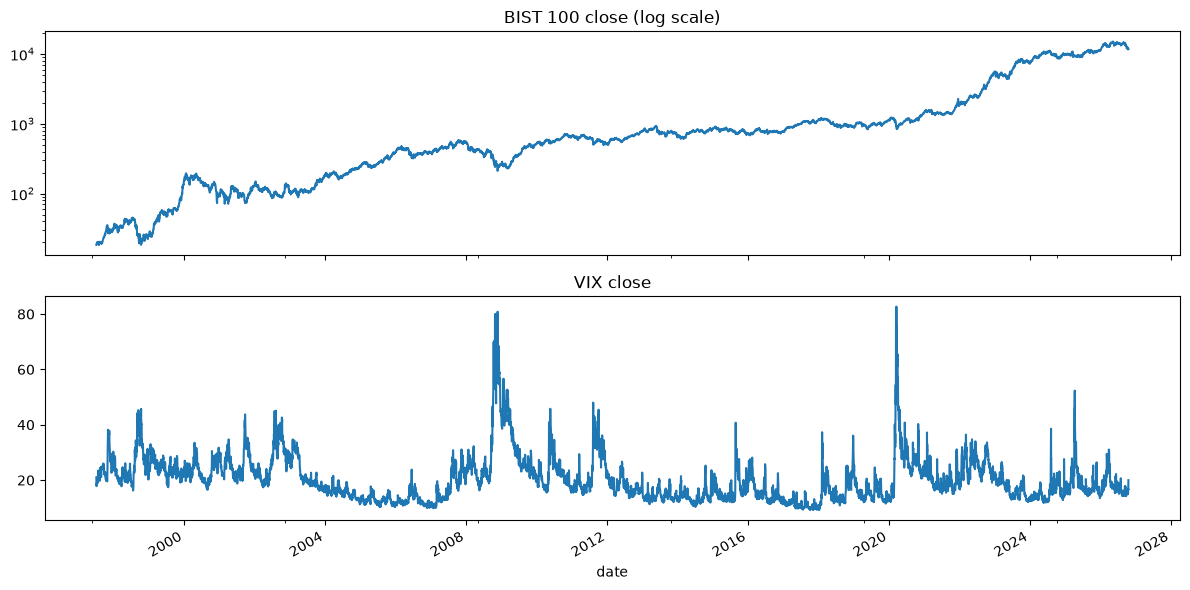

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
xu100["close"].plot(ax=axes[0], logy=True, title="BIST 100 close (log scale)")
vix["close"].plot(ax=axes[1], title="VIX close")
fig.tight_layout()

## 2. Daily returns

Volatility models work on daily log returns, `ln(close / previous close)`, not on prices.

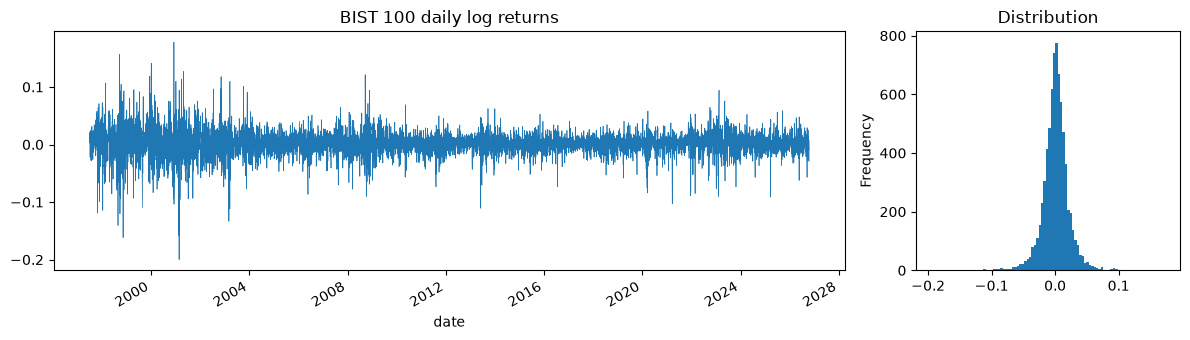

In [4]:
returns = log_returns(xu100["close"]).dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), width_ratios=[3, 1])
returns.plot(ax=axes[0], lw=0.5, title="BIST 100 daily log returns")
returns.plot.hist(ax=axes[1], bins=100, title="Distribution")
fig.tight_layout()

In [5]:
stats = {
    "mean (daily)": returns.mean(),
    "std (daily)": returns.std(),
    "annualized vol": returns.std() * np.sqrt(252),
    "skew": returns.skew(),
    "excess kurtosis": returns.kurt(),
}
pd.Series(stats).round(4)

mean (daily)       0.0009
std (daily)        0.0218
annualized vol     0.3459
skew              -0.1595
excess kurtosis    7.3284
dtype: float64

## 3. Data quality

Yahoo sometimes repeats the previous close on local holidays. Those fake zero-return days would pull volatility estimates down.

In [6]:
unchanged = returns[returns == 0]
zero_volume = (xu100["volume"] == 0).sum()
print(f"unchanged closes: {len(unchanged):,} of {len(returns):,} days")
print(f"zero-volume days: {zero_volume:,}")
unchanged.to_frame("log return")

unchanged closes: 4 of 7,316 days
zero-volume days: 27


,log return
date,
1997-08-27,0.0
1997-11-03,0.0
2020-12-04,0.0
2023-02-08,0.0


BIST and US trading days differ because of different holidays. That matters when VIX is matched to BIST dates.

In [7]:
only_bist = xu100.index.difference(vix.index)
only_us = vix.index.difference(xu100.index)
print(f"BIST days with no VIX value (US holidays): {len(only_bist):,}")
print(f"US days with no BIST value (Turkish holidays): {len(only_us):,}")

BIST days with no VIX value (US holidays): 232
US days with no BIST value (Turkish holidays): 287


## 4. Volatility clustering

Returns barely correlate with their own past, but their size (`|returns|`) does: calm and turbulent periods persist. GARCH and lagged-volatility features rely on this.

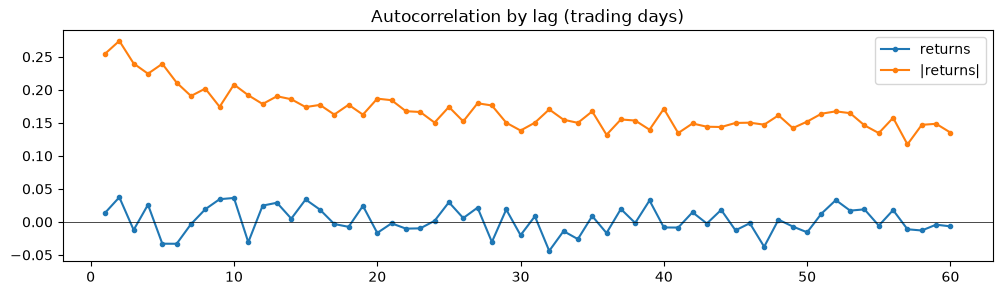

In [8]:
lags = range(1, 61)
acf = pd.DataFrame(
    {
        "returns": [returns.autocorr(lag) for lag in lags],
        "|returns|": [returns.abs().autocorr(lag) for lag in lags],
    },
    index=lags,
)
ax = acf.plot(figsize=(12, 3), marker=".", title="Autocorrelation by lag (trading days)")
ax.axhline(0, color="black", lw=0.5)
plt.show()

## 5. Realized volatility vs VIX

21-day realized volatility of BIST 100, annualized in % like VIX. VIX measures expected S&P 500 volatility, so as a BIST baseline it has to be rescaled.

correlation: 0.46


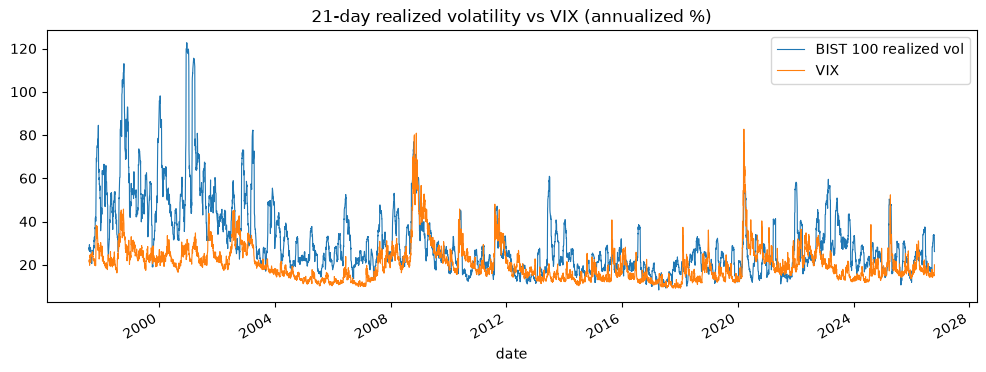

In [9]:
realized = realized_volatility(returns, 21)
both = pd.DataFrame({"BIST 100 realized vol": realized, "VIX": vix["close"]}).dropna()
print(f"correlation: {both.corr().iloc[0, 1]:.2f}")

both.plot(figsize=(12, 4), lw=0.8, title="21-day realized volatility vs VIX (annualized %)")
plt.show()

## 6. Forecast horizon

The target is realized volatility over the next *h* trading days. 1, 5, 10, 21 and 63 trading days are one day, one week, two weeks, one month and one quarter.

A horizon is only worth forecasting if the past says something about it. The table compares each target with two simple forecasts made at today's close: realized volatility over the past *h* days (naive), and the last VIX close before today.

- **mean** and **std**: the target's average level and spread, in annualized %.
- **corr**: whether a forecast moves up and down with the target.
- **MAE**: how far off a forecast is on average, in volatility points. VIX isn't rescaled here, so its MAE includes the gap between US and Turkish volatility levels.

In [10]:
horizons = [1, 5, 10, 21, 63]
vix_before = last_value_before(vix["close"], returns.index)

rows = {}
for h in horizons:
    target = forward_realized_volatility(returns, h)
    naive = realized_volatility(returns, h)
    rows[h] = {
        "mean": target.mean(),
        "std": target.std(),
        "naive corr": target.corr(naive),
        "naive MAE": (target - naive).abs().mean(),
        "VIX corr": target.corr(vix_before),
        "VIX MAE": (target - vix_before).abs().mean(),
    }
pd.DataFrame(rows).T.rename_axis("horizon").round(2)

,mean,std,naive corr,naive MAE,VIX corr,VIX MAE
horizon,,,,,,
1,23.66,25.27,0.25,20.76,0.23,16.08
5,28.66,19.43,0.55,12.28,0.35,12.86
10,29.63,17.93,0.61,10.57,0.38,12.67
21,30.38,16.64,0.65,9.38,0.39,12.83
63,31.24,15.06,0.70,8.06,0.37,13.25


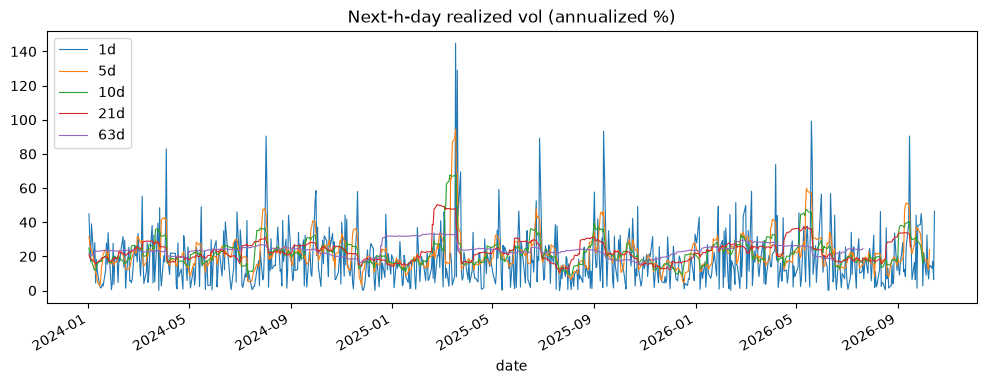

In [11]:
targets = pd.DataFrame({f"{h}d": forward_realized_volatility(returns, h) for h in horizons})
targets.loc["2024":].plot(figsize=(12, 4), lw=0.8, title="Next-h-day realized vol (annualized %)")
plt.show()

## 7. USD/TRY

Lira stress is the Turkey-specific risk that VIX misses. On Yahoo it's `TRY=X`, quoted in lira per dollar. FX data there is messier than index data, so check it first. A millionfold drop at the start of 2005 (a log return around -13.8) would mean the earlier history is still in old lira, from before six zeros were removed.

In [12]:
usdtry = load_prices("usdtry")
usdtry_returns = log_returns(usdtry["close"]).dropna()
first, last = usdtry.index[0], usdtry.index[-1]
print(f"{len(usdtry):,} rows, {first:%Y-%m-%d} to {last:%Y-%m-%d}")
print(f"duplicate dates: {usdtry.index.duplicated().sum()}")
print(f"unchanged closes: {(usdtry_returns == 0).sum():,} of {len(usdtry_returns):,} days")

# The 10 largest daily moves, in date order
usdtry_returns.loc[usdtry_returns.abs().nlargest(10).index].sort_index().to_frame("log return")

5,665 rows, 2005-01-03 to 2026-10-16
duplicate dates: 0
unchanged closes: 48 of 5,664 days


,log return
date,
2008-10-15,0.076034
2018-08-13,0.205379
2018-08-15,-0.086848
2018-08-16,-0.067803
2021-03-22,0.100654
2021-11-24,0.116772
2021-11-25,-0.073207
2021-12-21,-0.209041
2021-12-22,-0.093688


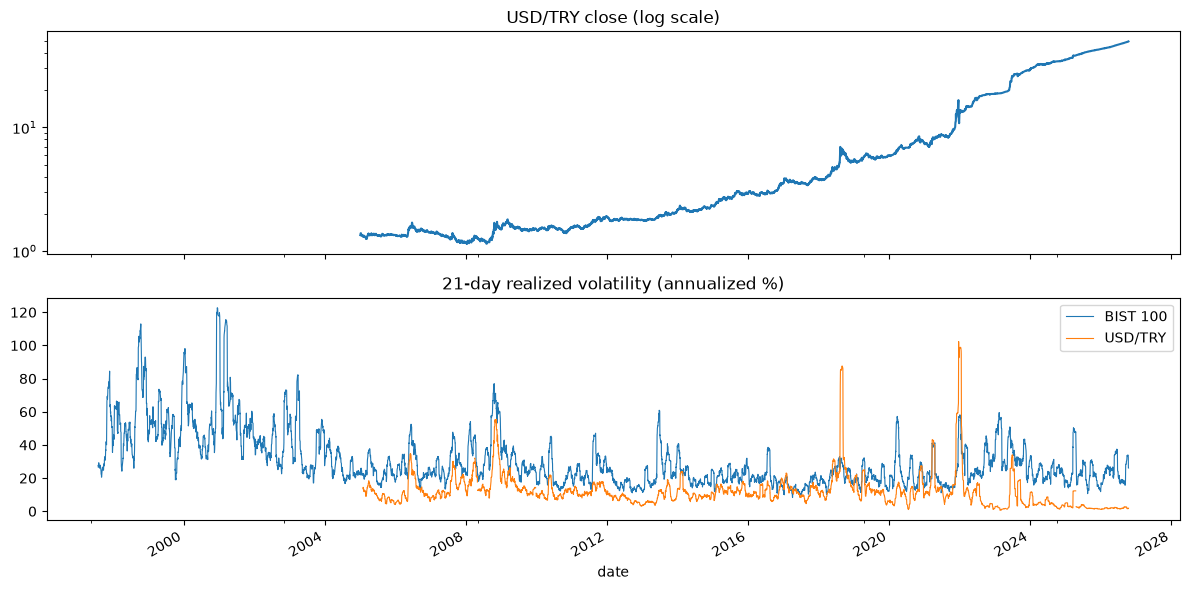

In [13]:
usdtry_volatility = realized_volatility(usdtry_returns, 21)
columns = {
    "BIST 100": realized_volatility(returns, 21),
    "USD/TRY": usdtry_volatility.reindex(returns.index),
}
vols = pd.DataFrame(columns)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
usdtry["close"].plot(ax=axes[0], logy=True, title="USD/TRY close (log scale)")
vols.plot(ax=axes[1], lw=0.8, title="21-day realized volatility (annualized %)")
fig.tight_layout()

Does lira volatility help predict BIST volatility? Every input below is known at BIST's close on the forecast date (VIX and USD/TRY through `last_value_before`), and all of them are compared on the same dates.

In [14]:
columns = {
    "target": forward_realized_volatility(returns, 21),
    "naive": realized_volatility(returns, 21),
    "VIX": last_value_before(vix["close"], returns.index),
    "USD/TRY vol": last_value_before(usdtry_volatility, returns.index),
}
comparison = pd.DataFrame(columns).dropna()
print(f"common sample: {comparison.index[0]:%Y-%m-%d} to {comparison.index[-1]:%Y-%m-%d}")
comparison.corr()["target"].drop("target").round(2)

common sample: 2005-02-02 to 2026-09-17


naive          0.45
VIX            0.32
USD/TRY vol    0.17
Name: target, dtype: float64

## Findings

- **Data is clean.** No break at the 2005 currency change or the 2020 index rescaling. Only 4 unchanged BIST closes in 7,316 days. USD/TRY starts in 2005 and has 48 unchanged closes in 5,664 days.
- **Two eras.** In 1997–2002, 21-day realized volatility is often 40–80% and peaks near 120%. From 2003 it mostly stays at 15–40%, with crisis spikes to 50–75%.
- **Fat tails.** The daily standard deviation is 2.2% (about 35% a year) and excess kurtosis is 7.3: extreme days are far more common than a normal distribution predicts.
- **Volatility clusters.** Autocorrelation of |returns| starts near 0.25 and is still about 0.14 after 60 days, while returns themselves stay near 0.
- **Horizon.** The naive forecast's correlation with the target rises from 0.25 (1 day) to 0.65 (21 days) and only reaches 0.70 at 63 days. At 21 days the target averages 30% (standard deviation 17) over 1997–2026; naive misses it by 9.4 points on average and raw VIX by 12.8. At 1 day the naive miss (20.8) is almost as large as the average level (23.7). Target: realized volatility over the next 21 trading days, which is also the window VIX covers.
- **Inputs, compared on 2005–2026.** Correlation with the next 21 days' volatility: naive 0.45, VIX 0.32, USD/TRY volatility 0.17. Lira volatility has been almost flat since late 2023, so it's an optional input to test, not a core one.
- **The crisis years flatter the numbers.** The naive correlation is 0.65 from 1997 but 0.45 from 2005. In the baselines notebook, training from 2003 beats training from 1997 on the same test period.
- **Alignment.** VIX and USD/TRY close after BIST and trade on other holidays, so each BIST day uses their last value before it (`last_value_before`).